# **KeyWordSearch**

this notebook is for implementing the keyword search method including the two comon used strategies : 
- Key word search by using TF-IDF method
- Key word search by using BM25 method

In [92]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import BertTokenizer
from rank_bm25 import BM25Okapi
import chromadb

tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-cased')

## **TF-IDF strategy**

In [93]:
def _rank_cases(scores, candidate_indices, index, top_k):
    if top_k <= 0:
        raise ValueError("top_k must be a positive integer")

    best_chunks = {}
    for chunk_index in candidate_indices:
        metadata = index["metadatas"][chunk_index]
        source_id = metadata.get("source_id")
        if not source_id:
            raise ValueError(f"Chunk {index['ids'][chunk_index]} has no source_id metadata")

        score = float(scores[chunk_index])
        current = best_chunks.get(source_id)
        if current is None or score > current["score"]:
            best_chunks[source_id] = {
                "document": index["documents"][chunk_index],
                "score": score,
                "id": index["ids"][chunk_index],
                "source_id": source_id,
                "metadatas": metadata,
            }

    ranked_cases = sorted(
        best_chunks.values(),
        key=lambda result: (-result["score"], result["source_id"]),
    )
    return ranked_cases[:top_k]


def KeywordSearch_TFIDF(query: str, top_k: int, index: dict) -> list:
    query_vector = index["tfidf_vectorizer"].transform([query])
    scores = cosine_similarity(query_vector, index["tfidf_vectors"]).ravel()
    candidate_indices = [i for i, score in enumerate(scores) if score > 0]
    return _rank_cases(scores, candidate_indices, index, top_k)

## **BM25 Strategy**

In [94]:
def KeywordSearch_BM25(query: str, top_k: int, index: dict) -> list:
    query_tokens = tokenizer(query, add_special_tokens=False)["input_ids"]
    if not query_tokens:
        return []

    scores = index["bm25_index"].get_scores(query_tokens)
    unique_query_tokens = set(query_tokens)
    candidate_indices = [
        i for i, document_tokens in enumerate(index["bm25_tokens"])
        if unique_query_tokens.intersection(document_tokens)
    ]
    return _rank_cases(scores, candidate_indices, index, top_k)

# **Testing the two strategies**

In [95]:
path = r"C:\Users\aliai\Desktop\M2 I2A\RAG Agentique\Backend\Collections"

In [96]:
client = chromadb.PersistentClient(path=path)

In [97]:
collection = client.get_collection(
    name="jurisprudence"
)

In [98]:
stored = collection.get(include=["documents", "metadatas"])
keyword_documents = stored["documents"]
if not keyword_documents:
    raise ValueError("The Chroma collection contains no documents")
if not (len(keyword_documents) == len(stored["ids"]) == len(stored["metadatas"])):
    raise ValueError("Chroma returned misaligned documents, IDs, and metadata")

keyword_index = {
    "documents": keyword_documents,
    "ids": stored["ids"],
    "metadatas": stored["metadatas"],
    "tfidf_vectorizer": TfidfVectorizer(),
}
keyword_index["tfidf_vectors"] = keyword_index["tfidf_vectorizer"].fit_transform(
    keyword_documents
)
keyword_index["bm25_tokens"] = tokenizer(
    keyword_documents,
    add_special_tokens=False,
    truncation=False,
)["input_ids"]
keyword_index["bm25_index"] = BM25Okapi(
    keyword_index["bm25_tokens"],
    k1=1.25,
)

print(f"Indexes built for {len(keyword_documents)} chunks")

Indexes built for 12370 chunks


## **TF-IDF strategy**

In [99]:
tf_idf_results = KeywordSearch_TFIDF(
    query="contrat de travail",
    top_k=2,
    index=keyword_index,
)

## **BM25 strategy**

In [100]:
bm25_results = KeywordSearch_BM25(
    query="contrat de travail",
    top_k=2,
    index=keyword_index,
)

# **Evaluation of the search strategy based on searching the cases**

Cette Evaluation compare TF-IDF et BM25 sur les m?mes requ?tes, en classant des affaires distinctes (d?dupliqu?es par `source_id`) et non des chunks. Le score d?une affaire est le meilleur score de ses chunks. Les labels de pertinence du fichier restent provisoires et doivent ?tre valid?s manuellement.

In [101]:
import json
from pathlib import Path

candidate_paths = [
    Path.cwd() / "keyword_evaluation.json",
    Path.cwd() / "Backend" / "Retreival" / "keyword_evaluation.json",
]
file_path = next((candidate for candidate in candidate_paths if candidate.is_file()), None)
if file_path is None:
    raise FileNotFoundError(
        "keyword_evaluation.json was not found from the current working directory"
    )

with file_path.open(encoding="utf-8") as file:
    evaluation_data = json.load(file)

queries = evaluation_data["queries"]

## Evaluation fiable au niveau des affaires

Les deux strat?gies sont ?valu?es sur les m?mes requ?tes et sur les m?mes profondeurs (`k = 5` et `k = 10`). Chaque fonction de recherche renvoie d?j? des `source_id` uniques, class?s selon le meilleur score d?un de leurs chunks. La pr?cision utilise `k` comme d?nominateur m?me si moins de `k` affaires ont ?t? trouv?es. Le rappel est calcul? par rapport ? tous les `source_id` pertinents annot?s. MRR et nDCG sont calcul?s jusqu?? `k = 10` avec une pertinence binaire.

Les labels de `keyword_evaluation.json` sont provisoires : les m?triques sont indicatives jusqu?? validation manuelle des affaires pertinentes.

In [108]:
from math import log2
from statistics import mean

K_VALUES = (5, 10, 20, 30)


def evaluate_strategy(search_function, method_name, evaluation_queries, index):
    per_query = []
    max_k = max(K_VALUES)

    for query_data in evaluation_queries:
        relevant_ids = set(query_data["relevant_source_ids"])
        if not relevant_ids:
            raise ValueError(f"{query_data['query_id']} has no relevance labels")

        ranked_results = search_function(
            query=query_data["query"],
            top_k=max_k,
            index=index,
        )
        ranked_ids = [result["source_id"] for result in ranked_results]
        if len(ranked_ids) != len(set(ranked_ids)):
            raise ValueError(f"{method_name} returned duplicate cases")

        row = {
            "method": method_name,
            "query_id": query_data["query_id"],
            "query": query_data["query"],
            "retrieved_source_ids": ranked_ids,
        }
        relevant_ranks = [
            rank for rank, source_id in enumerate(ranked_ids, start=1)
            if source_id in relevant_ids
        ]
        row["mrr@10"] = 1 / relevant_ranks[0] if relevant_ranks else 0.0

        for k in K_VALUES:
            found = sum(source_id in relevant_ids for source_id in ranked_ids[:k])
            row[f"precision@{k}"] = found / k
            row[f"recall@{k}"] = found / len(relevant_ids)

            dcg = sum(
                1 / log2(rank + 1)
                for rank, source_id in enumerate(ranked_ids[:k], start=1)
                if source_id in relevant_ids
            )
            ideal_count = min(len(relevant_ids), k)
            ideal_dcg = sum(
                1 / log2(rank + 1)
                for rank in range(1, ideal_count + 1)
            )
            row[f"ndcg@{k}"] = dcg / ideal_dcg if ideal_dcg else 0.0

        per_query.append(row)

    summary = {"method": method_name, "queries": len(per_query)}
    for metric in (
        "precision@5", "recall@5", "ndcg@5",
        "precision@10", "recall@10", "ndcg@10", "mrr@10",
        "precision@20", "recall@20", "ndcg@20", 
        "precision@30", "recall@30", "ndcg@30", 
    ):
        summary[metric] = mean(row[metric] for row in per_query)
    return summary, per_query

In [109]:
evaluation_summary = []
evaluation_details = []
for method_name, search_function in (
    ("TF-IDF", KeywordSearch_TFIDF),
    ("BM25", KeywordSearch_BM25),
):
    summary, details = evaluate_strategy(
        search_function,
        method_name,
        queries,
        keyword_index,
    )
    evaluation_summary.append(summary)
    evaluation_details.extend(details)

print("Moyennes macro par requ?te (labels provisoires) :")
for result in evaluation_summary:
    print(result)

Moyennes macro par requ?te (labels provisoires) :
{'method': 'TF-IDF', 'queries': 15, 'precision@5': 0.22666666666666668, 'recall@5': 0.5444444444444444, 'ndcg@5': 0.4916234285368582, 'precision@10': 0.12666666666666668, 'recall@10': 0.5722222222222222, 'ndcg@10': 0.49631843887155713, 'mrr@10': 0.5655555555555556, 'precision@20': 0.08, 'recall@20': 0.6222222222222222, 'ndcg@20': 0.5171800476421771, 'precision@30': 0.07555555555555556, 'recall@30': 0.7166666666666667, 'ndcg@30': 0.5535198940888519}
{'method': 'BM25', 'queries': 15, 'precision@5': 0.2, 'recall@5': 0.5111111111111111, 'ndcg@5': 0.44381032299573525, 'precision@10': 0.11333333333333333, 'recall@10': 0.5555555555555556, 'ndcg@10': 0.4643721515174707, 'mrr@10': 0.45989010989010987, 'precision@20': 0.07, 'recall@20': 0.6055555555555555, 'ndcg@20': 0.4851357982897333, 'precision@30': 0.057777777777777775, 'recall@30': 0.6777777777777778, 'ndcg@30': 0.5091118152834752}


## Visualisation des résultats

Les graphiques comparent les moyennes des métriques pour TF-IDF et BM25 aux différentes profondeurs `k`, puis montrent le rappel@10 pour chaque requête. Ils utilisent `evaluation_summary` et `evaluation_details` calculés plus haut ; relance d’abord les cellules d’évaluation après toute modification des données ou des métriques.

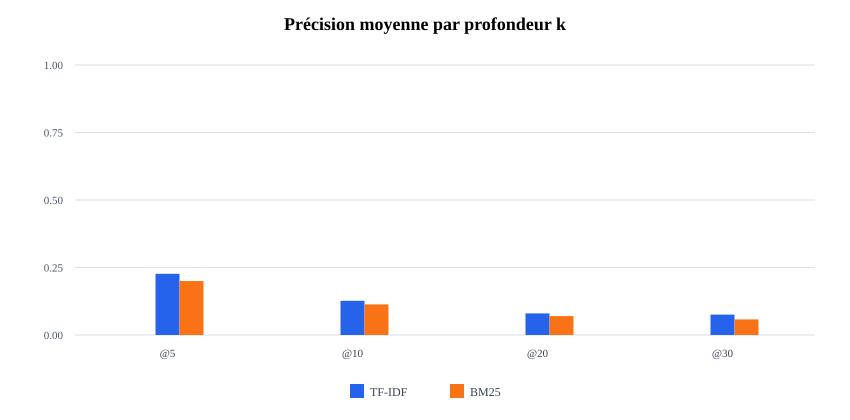

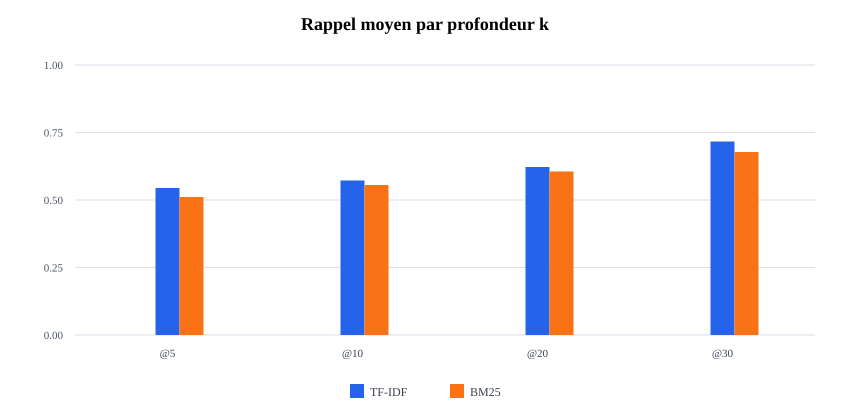

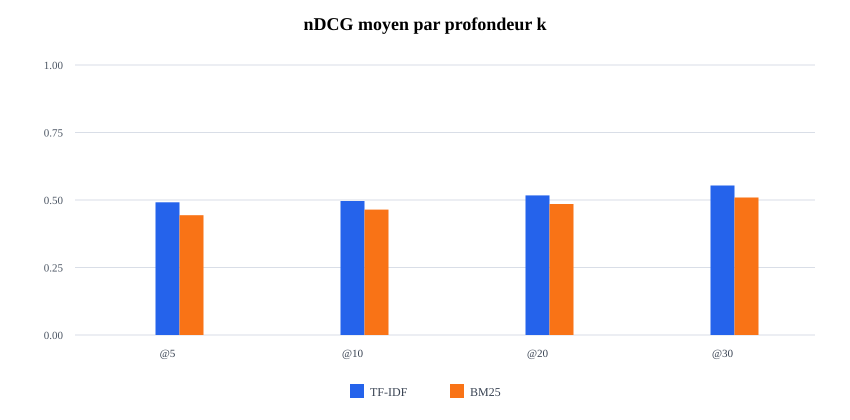

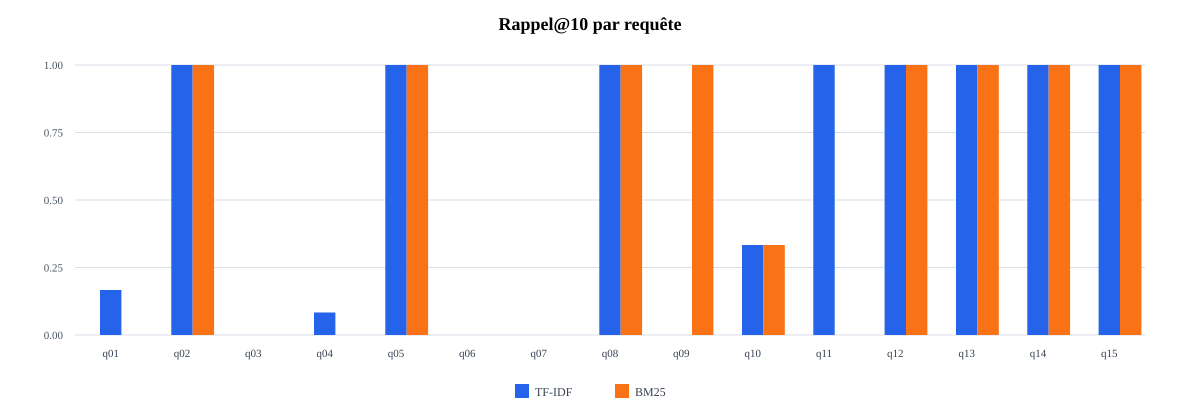

In [110]:
from html import escape
from IPython.display import SVG, display


def display_comparison_chart(title, labels, tfidf_values, bm25_values):
    width = max(850, 70 * len(labels) + 130)
    height = 420
    left, right, top, bottom = 75, 35, 65, 85
    plot_width = width - left - right
    plot_height = height - top - bottom
    group_width = plot_width / len(labels)
    bar_width = min(24, group_width * 0.3)
    elements = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="{width / 2}" y="30" text-anchor="middle" font-size="18" font-weight="bold">{escape(title)}</text>',
    ]

    for tick in range(5):
        value = tick / 4
        y = top + plot_height * (1 - value)
        elements.append(f'<line x1="{left}" y1="{y:.1f}" x2="{width - right}" y2="{y:.1f}" stroke="#d9dee7"/>')
        elements.append(f'<text x="{left - 12}" y="{y + 4:.1f}" text-anchor="end" font-size="11" fill="#4b5563">{value:.2f}</text>')

    for index, label in enumerate(labels):
        center = left + group_width * (index + 0.5)
        for value, offset, color, method in (
            (tfidf_values[index], -bar_width / 2, "#2563eb", "TF-IDF"),
            (bm25_values[index], bar_width / 2, "#f97316", "BM25"),
        ):
            bar_height = max(0, min(1, value)) * plot_height
            x = center + offset
            y = top + plot_height - bar_height
            elements.append(f'<rect x="{x:.1f}" y="{y:.1f}" width="{bar_width:.1f}" height="{bar_height:.1f}" fill="{color}"><title>{escape(label)} — {method}: {value:.3f}</title></rect>')
        elements.append(f'<text x="{center:.1f}" y="{top + plot_height + 22}" text-anchor="middle" font-size="11" fill="#374151">{escape(label)}</text>')

    legend_y = height - 24
    for index, (method, color) in enumerate((("TF-IDF", "#2563eb"), ("BM25", "#f97316"))):
        x = width / 2 - 75 + index * 100
        elements.append(f'<rect x="{x:.1f}" y="{legend_y - 12}" width="14" height="14" fill="{color}"/>')
        elements.append(f'<text x="{x + 20:.1f}" y="{legend_y}" font-size="12" fill="#374151">{method}</text>')

    elements.append('</svg>')
    display(SVG("\n".join(elements)))


tfidf_summary = next(item for item in evaluation_summary if item["method"] == "TF-IDF")
bm25_summary = next(item for item in evaluation_summary if item["method"] == "BM25")
k_values = K_VALUES

display_comparison_chart(
    "Précision moyenne par profondeur k",
    [f"@{k}" for k in k_values],
    [tfidf_summary[f"precision@{k}"] for k in k_values],
    [bm25_summary[f"precision@{k}"] for k in k_values],
)
display_comparison_chart(
    "Rappel moyen par profondeur k",
    [f"@{k}" for k in k_values],
    [tfidf_summary[f"recall@{k}"] for k in k_values],
    [bm25_summary[f"recall@{k}"] for k in k_values],
)
display_comparison_chart(
    "nDCG moyen par profondeur k",
    [f"@{k}" for k in k_values],
    [tfidf_summary[f"ndcg@{k}"] for k in k_values],
    [bm25_summary[f"ndcg@{k}"] for k in k_values],
)

tfidf_by_query = {
    row["query_id"]: row
    for row in evaluation_details
    if row["method"] == "TF-IDF"
}
bm25_by_query = {
    row["query_id"]: row
    for row in evaluation_details
    if row["method"] == "BM25"
}
query_ids = [query["query_id"] for query in queries]
display_comparison_chart(
    "Rappel@10 par requête",
    query_ids,
    [tfidf_by_query[query_id]["recall@10"] for query_id in query_ids],
    [bm25_by_query[query_id]["recall@10"] for query_id in query_ids],
)